In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

## Limpieza y analisis exploratorio

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.shape

(100000, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [6]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [7]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


habian algunos datos con mayusculas y cosas asi

In [8]:
df["smoking_history"] = (
    df["smoking_history"]
    .str.lower()
)

df["gender"] = (
    df["gender"]
    .str.lower()
)

ver variables categoricas

C:\Users\1511r\AppData\Local\Temp\ipykernel_23756\1525985914.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[i].set_xticklabels(ax[i].get_xticklabels(),rotation=30)
C:\Users\1511r\AppData\Local\Temp\ipykernel_23756\1525985914.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[i].set_xticklabels(ax[i].get_xticklabels(),rotation=30)


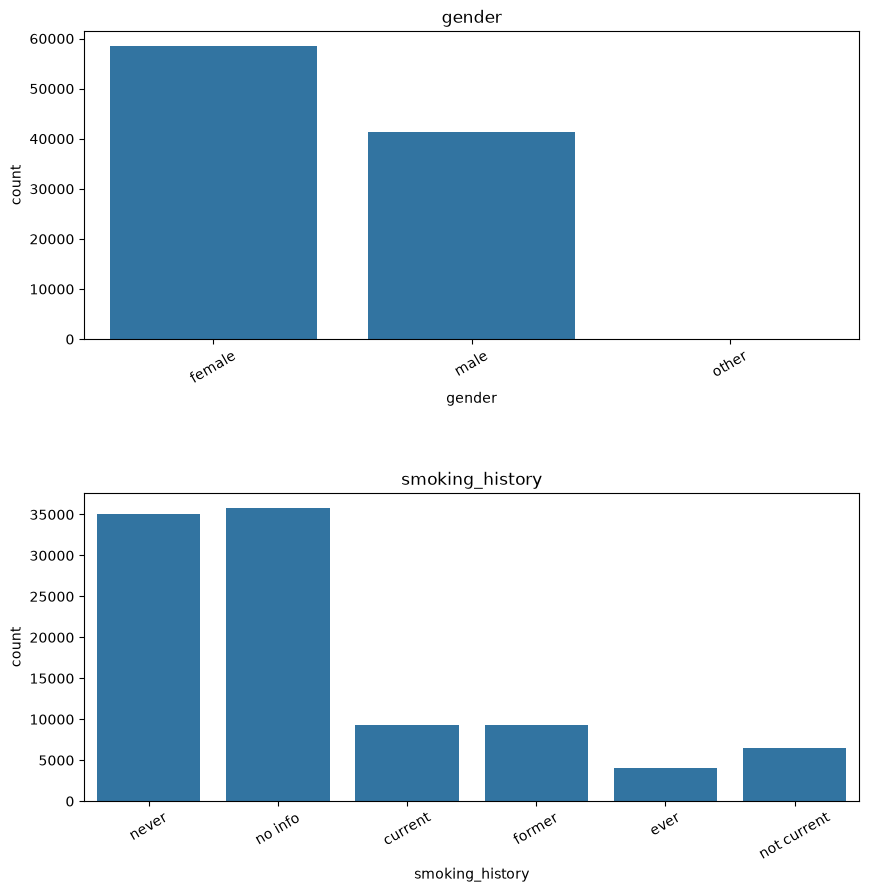

In [9]:
col_cat = ["gender","smoking_history"]

# Gráficos de barras de conteo
fig, ax = plt.subplots(nrows=len(col_cat), ncols=1, figsize=(10,10))
fig.subplots_adjust(hspace=0.5)

for i, col in enumerate(col_cat):
  sns.countplot(x=col, data=df, ax=ax[i])
  ax[i].set_title(col)
  ax[i].set_xticklabels(ax[i].get_xticklabels(),rotation=30)

In [10]:
(df["gender"] == "other").sum()

np.int64(18)

quito los que tienen gender = Other, al ser solo 18 de 100000 datos no afecta al modelo quitarlos

In [11]:
df = df[df["gender"] != "other"]

un problema a lidiar es No info en smoking_history

In [12]:
(df["smoking_history"] == "no info").sum()

np.int64(35810)

In [13]:
df["smoking_history"].value_counts()

smoking_history
no info        35810
never          35092
former          9352
current         9286
not current     6439
ever            4003
Name: count, dtype: int64

para ver si el fumar o no y eso afecta

In [14]:
pd.crosstab(
    df["smoking_history"],
    df["diabetes"],
    normalize="index"
).round(3)

diabetes,0,1
smoking_history,,
current,0.898,0.102
ever,0.882,0.118
former,0.830,0.170
never,0.905,0.095
no info,0.959,0.041
not current,0.893,0.107


dejo esto asi por is tengo que eliminar, ya que es un 35% de los datos

In [15]:
# df = df[df["smoking_history"] != "no info"]

In [16]:
df.loc[df["diabetes"] == 1, ["smoking_history"]].value_counts()

smoking_history
never              3346
former             1590
no info            1454
current             948
not current         690
ever                472
Name: count, dtype: int64

In [17]:
pd.crosstab(
    pd.cut(df["age"], bins=[0, 30, 45, 60, 100]),
    df["smoking_history"],
    normalize="index"
).round(2)

smoking_history,current,ever,former,never,no info,not current
age,,,,,,
"(0, 30]",0.07,0.02,0.02,0.31,0.53,0.05
"(30, 45]",0.13,0.05,0.07,0.41,0.27,0.07
"(45, 60]",0.13,0.05,0.12,0.38,0.26,0.07
"(60, 100]",0.06,0.05,0.18,0.34,0.28,0.08


In [18]:
# buscar outliers, valores con 0 donde no van, como glucosa y asi, mapa de calor

checar variables numericas
checare valores atipicos

In [19]:
cols_num = ['age', 'bmi', 'HbA1c_level',
            'blood_glucose_level']

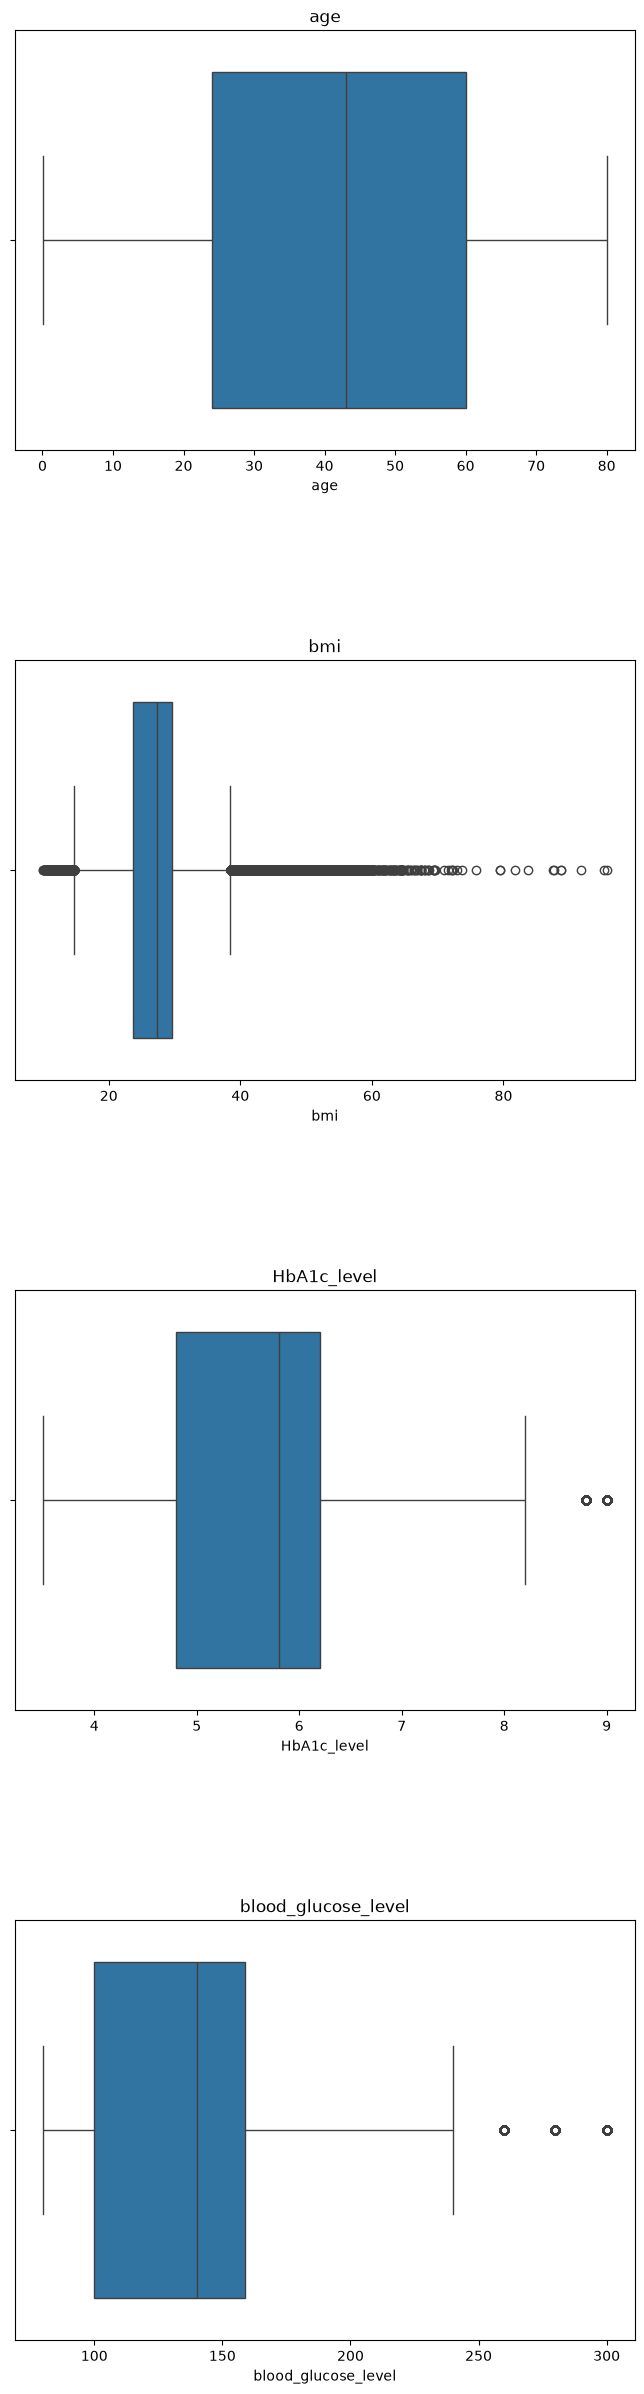

In [20]:
fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(8,30))
fig.subplots_adjust(hspace=0.5)

for i, col in enumerate(cols_num):
    sns.boxplot(x=col, data=df, ax=ax[i])
    ax[i].set_title(col)

bmi tiene muchos valores atipicos

In [21]:
bmi_q1 = df["bmi"].quantile(0.25)
bmi_q3 = df["bmi"].quantile(0.75)

bmi_IQR = bmi_q3 - bmi_q1

bmi_limite_inf = bmi_q1 - 1.5 * bmi_IQR
bmi_limite_sup = bmi_q3 + 1.5 * bmi_IQR

print(f"bmi_q1: {bmi_q1}")
print(f"bmi_q3: {bmi_q3}")
print(f"bmi_IQR: {bmi_IQR}")
print(f"bmi_limite_inf: {bmi_limite_inf}")
print(f"bmi_limite_sup: {bmi_limite_sup}")

bmi_outliers = df[
    (df["bmi"] < bmi_limite_inf) |
    (df["bmi"] > bmi_limite_sup)
]

print("Cantidad de outliers:", len(bmi_outliers))


bmi_q1: 23.63
bmi_q3: 29.58
bmi_IQR: 5.949999999999999
bmi_limite_inf: 14.705
bmi_limite_sup: 38.504999999999995
Cantidad de outliers: 7085


dejare estos valores tal cual, ya que un bmi alto tiene que ver con diabetes

In [22]:
df["diabetes"].value_counts()

diabetes
0    91482
1     8500
Name: count, dtype: int64

## ahora si con los modelos

In [23]:
# usare regresion logistica, random forest y XGBoost

In [24]:
df_encoded = pd.get_dummies(df, drop_first=True)

In [25]:
X = df_encoded.drop(columns=["diabetes"])
y = df_encoded["diabetes"]  # lo que se va a predecir

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Entrenando el modelo...

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     18297
           1       0.78      0.75      0.76      1700

    accuracy                           0.96     19997
   macro avg       0.88      0.87      0.87     19997
weighted avg       0.96      0.96      0.96     19997


--- MATRIZ DE CONFUSIÓN ---


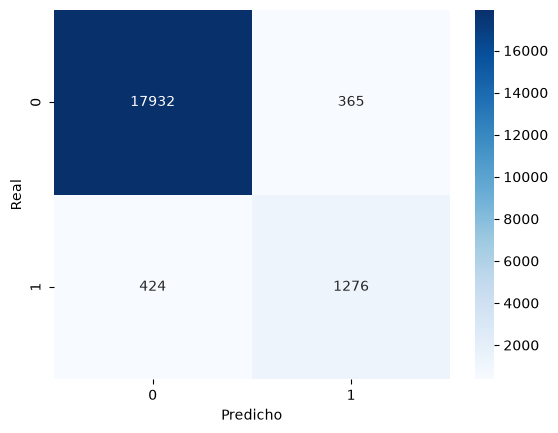

In [29]:
# ==========================================
# PASO 6: Entrenar el Modelo (con clase balanceada)
# ==========================================
print("Entrenando el modelo...")
model = RandomForestClassifier(class_weight="balanced", random_state=42)
model.fit(X_train, y_train)


# ==========================================
# PASO 7: Predicción y Evaluación Honesta
# ==========================================
y_pred = model.predict(X_test)

# Reporte de métricas (Precision, Recall, F1-Score)
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred))

# # Matriz de confusión visual
# print("\n--- MATRIZ DE CONFUSIÓN ---")
# conf_matrix = confusion_matrix(y_test, y_pred)
# sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
# plt.xlabel("Predicho")
# plt.ylabel("Real")
# plt.show()